# My Tu Verras, workshop 3 — Reading your errors

You have a model and a number: RMSE around 4.7. The project hands you a function printing three
metrics and leaves it there. Today we use them properly, and then do the thing that actually
improves models: **look at where the errors are**.

1. **MAE, MSE, RMSE** — three numbers, three different questions.
2. **The worst prediction**, and why it is not a surprise.
3. **The residual plot** — what the textbook promises, and what this data actually does.
4. **Heteroscedasticity**, the log transform, and the honest answer about whether it fixes anything.

Everything on Qwasar's `boston.csv`.

In [ ]:
# ABOUTME: My Tu Verras workshop 3 - error metrics and residual diagnosis on boston.csv.
# ABOUTME: The U-shaped residual spread, Breusch-Pagan, the log transform, and censoring at 50.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

from pathlib import Path

def qwasar_file(name):
    """Locate a dataset fetched by workshops/get_data.py, from wherever this notebook was opened."""
    for up in range(4):
        p = Path(*([".."] * up), "data", name)
        if p.exists():
            return p
    raise FileNotFoundError(
        f"{name} is missing. Run `uv run get_data.py` in the workshops/ folder first - "
        "these notebooks only ever use the real datasets Qwasar provides.")

boston = pd.read_csv(qwasar_file("boston.csv"))
TARGET = "MDEV"
FEATURES = [c for c in boston.columns if c != TARGET]

def split(df, seed=42):
    shuffled = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    a, b = int(0.70 * len(df)), int(0.85 * len(df))
    return shuffled[:a], shuffled[a:b], shuffled[b:]

train, val, test = split(boston)
model = LinearRegression().fit(train[FEATURES], train[TARGET])
predicted = model.predict(val[FEATURES])
print(f"{len(train)} train / {len(val)} validation towns")

354 train / 76 validation towns


## 1. Three metrics, three questions

The project gives you this function:

```python
def print_model_prediction_evaluator(base_test, prediction):
    print('Mean Absolute Error:', metrics.mean_absolute_error(base_test, prediction))
    print('Mean Squared Error:', metrics.mean_squared_error(base_test, prediction))
    print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(base_test, prediction)))
```

Three numbers, and students usually quote whichever is smallest. They answer different questions:

- **MAE** — the typical miss, in dollars. Every error counts once.
- **MSE** — errors squared, so a miss of 10 hurts *a hundred times* more than a miss of 1. Not in
  dollars: it is in dollars **squared**, which is why you never report it to a client.
- **RMSE** — the square root of MSE, back in dollars, but still dominated by the big misses.

### Exercise 1 — compute all three, and read the gap

In [ ]:
def print_model_prediction_evaluator(base_test, prediction):
    """MAE, MSE and RMSE, as the project asks."""
    print("Mean Absolute Error:", mean_absolute_error(base_test, prediction))
    print("Mean Squared Error:", mean_squared_error(base_test, prediction))
    print("Root Mean Squared Error:", np.sqrt(mean_squared_error(base_test, prediction)))

print_model_prediction_evaluator(val[TARGET], predicted)

mae = float(mean_absolute_error(val[TARGET], predicted))
rmse = float(np.sqrt(mean_squared_error(val[TARGET], predicted)))
print(f"\nRMSE / MAE = {rmse / mae:.2f}")

Mean Absolute Error: 3.62207956208715
Mean Squared Error: 22.238273042099923
Root Mean Squared Error: 4.71574734714445

RMSE / MAE = 1.30


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("both computed", lambda: mae is not None and rmse is not None)
check("RMSE is the larger of the two", lambda: rmse > mae)

  both computed: PASS
  RMSE is the larger of the two: PASS


True

**MAE 3.62, RMSE 4.72.** The typical town is missed by about **$3 600**, yet the RMSE says 4.72.

That gap is information, not noise. RMSE equals MAE only when every error is the same size; the
further apart they drift, the more a few large misses are dominating. A ratio of 1.3 says: *most
predictions are decent, a handful are bad.*

**Rule of thumb:** report MAE when you want "how far off am I typically", RMSE when large errors
are disproportionately costly. Quote both and the gap tells your reader something extra. Never
quote MSE to a non-specialist — the units are meaningless.

## 2. Find the worst prediction

The fastest route to understanding a model is its biggest failure.

### Exercise 2

In [ ]:
errors = val.assign(predicted=predicted)
errors["error"] = (errors.predicted - errors[TARGET]).abs()
worst = errors.nlargest(5, "error")[[TARGET, "predicted", "error", "RM", "LSTAT"]]
print(worst.round(2).to_string())
print(f"\nworst single miss: {errors.error.max():.2f} on a town priced {worst[TARGET].iloc[0]}")
errors = errors
worst

     MDEV  predicted  error    RM  LSTAT
414  50.0      36.27  13.73  7.49   1.73
417   7.2      17.88  10.68  6.34  20.32
379  50.0      39.54  10.46  7.80   1.92
389  33.0      23.12   9.88  7.10   8.05
370  50.0      40.38   9.62  8.30   7.44

worst single miss: 13.73 on a town priced 50.0


,MDEV,predicted,error,RM,LSTAT
414,50.0,36.267028,13.732972,7.489,1.73
417,7.2,17.879988,10.679988,6.343,20.32
379,50.0,39.537698,10.462302,7.802,1.92
389,33.0,23.116390,9.883610,7.104,8.05
370,50.0,40.384450,9.615550,8.297,7.44


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("errors computed", lambda: errors is not None and "error" in errors.columns)
check("the worst miss is large", lambda: errors.error.max() > 10)
check("and it is a censored town", lambda: errors.nlargest(1, "error")[TARGET].iloc[0] == 50.0)

  errors computed: PASS
  the worst miss is large: PASS
  and it is a censored town: PASS


True

Read that last check again: **the single worst prediction in the model is a town priced at exactly
50.0** — one of the sixteen censored towns you found in workshop 1.

The model predicts something like 36 for a town recorded at 50. It may not even be wrong: the true
price was *above* 50 and got clipped, so the model is being penalised for a number that was never
measured. You cannot fix this with a better model. You can only know it.

## 3. The residual plot

A residual is actual minus predicted, one per town. Plotted against the prediction, you are
looking for **nothing** — a shapeless band around zero. Any structure is signal the model missed.

The textbook failure mode is the **cone**: errors fanning out as predictions grow, called
*heteroscedasticity*. Let us see whether this data does that.

 mean_prediction  residual_std
           11.61          4.44
           18.52          3.39
           21.82          2.20
           25.89          5.70
           34.03          6.00


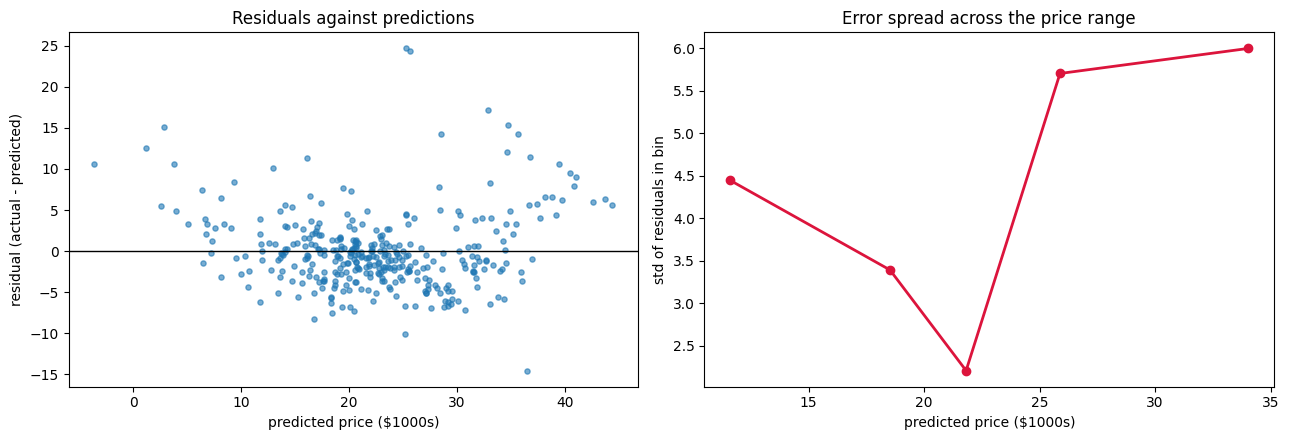

In [ ]:
fitted = model.predict(train[FEATURES])
residual = train[TARGET] - fitted

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(fitted, residual, s=14, alpha=0.6)
axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("predicted price ($1000s)"); axes[0].set_ylabel("residual (actual - predicted)")
axes[0].set_title("Residuals against predictions")

# The spread, measured rather than eyeballed: standard deviation within five equal-size bins.
bins = pd.qcut(fitted, 5, labels=False)
spread = pd.DataFrame({"mean_prediction": [fitted[bins == i].mean() for i in range(5)],
                       "residual_std":    [residual[bins == i].std() for i in range(5)]})
axes[1].plot(spread.mean_prediction, spread.residual_std, "o-", lw=2, color="crimson")
axes[1].set_xlabel("predicted price ($1000s)"); axes[1].set_ylabel("std of residuals in bin")
axes[1].set_title("Error spread across the price range")
plt.tight_layout()
print(spread.round(2).to_string(index=False))

That is **not a cone. It is a U.**

On this split the spread runs 4.44, 3.39, **2.20**, 5.70, 5.86 across the five bins: widest at the
cheap end, narrowest in the middle, widest again at the expensive end. The model is most reliable
for ordinary towns and least reliable at both extremes — and across 30 different splits, the middle
bin is the narrowest **every single time**.

So "is it heteroscedastic?" is the wrong first question. The right one is **"what shape, and
why?"**:

- **The expensive end** is inflated by the censored towns. Those 50.0s are scattered among the
  model's high predictions and each one contributes a large, irreducible error.
- **The cheap end** is a different story: the cheapest towns are the ones where `LSTAT` is extreme
  and the relationship bends. A straight line cannot follow a curve, so it misses in both
  directions there.

### Exercise 3 — confirm it numerically

Eyeballing a plot is not evidence. The **Breusch-Pagan** test asks whether the squared residuals
can be predicted from the features — if they can, the error variance is not constant.

In [ ]:
import scipy.stats as st

def breusch_pagan(X, residuals):
    """Return (LM statistic, p-value). Regress the SQUARED residuals on the features:
    if they are predictable, the variance is not constant."""
    aux = LinearRegression().fit(X, residuals ** 2)
    r2 = aux.score(X, residuals ** 2)
    lm = len(X) * r2
    return float(lm), float(st.chi2.sf(lm, X.shape[1]))

lm, p = breusch_pagan(train[FEATURES], residual)
print(f"Breusch-Pagan LM = {lm:.1f}, p = {p:.2e}")
print("heteroscedastic" if p < 0.05 else "no evidence of heteroscedasticity")

Breusch-Pagan LM = 49.4, p = 3.77e-06
heteroscedastic


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("the test ran", lambda: lm is not None and p is not None)
check("it detects non-constant variance", lambda: p < 0.05)

  the test ran: PASS
  it detects non-constant variance: PASS


True

**LM = 49.4, p = 3.8e-06.** Significant on all 30 splits. The variance really is not constant — the test
agrees with the plot, it just cannot tell you the shape. That is what the plot is for.

## 4. Does the log transform fix it?

The standard prescription for heteroscedasticity is to model `log(price)` instead of `price`:
compressing the top of the scale should even out the spread. In workshop 2 you measured that
log(price) **improves RMSE on 30 splits out of 30**.

So it works. But work out *what* it fixed before you write that sentence in your report.

### Exercise 4 — re-run the diagnosis after the transform

In [ ]:
log_model = LinearRegression().fit(train[FEATURES], np.log(train[TARGET]))
log_fitted = log_model.predict(train[FEATURES])
log_residual = np.log(train[TARGET]) - log_fitted

lm_log, p_log = breusch_pagan(train[FEATURES], log_residual)
print(f"Breusch-Pagan before : LM = {lm:.1f}, p = {p:.2e}")
print(f"Breusch-Pagan after  : LM = {lm_log:.1f}, p = {p_log:.2e}")

log_bins = pd.qcut(log_fitted, 5, labels=False)
after = [log_residual[log_bins == i].std() for i in range(5)]
print("\nresidual spread by bin, log space:", np.round(after, 3))
print("relative spread before            :", np.round(spread.residual_std.values / spread.mean_prediction.values, 3))

Breusch-Pagan before : LM = 49.4, p = 3.77e-06
Breusch-Pagan after  : LM = 56.5, p = 2.16e-07

residual spread by bin, log space: [0.276 0.163 0.112 0.177 0.164]
relative spread before            : [0.383 0.183 0.101 0.22  0.176]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("the test ran again", lambda: lm_log is not None)
check("it is STILL heteroscedastic", lambda: p_log < 0.05)

  the test ran again: PASS
  it is STILL heteroscedastic: PASS


True

Here is the honest result, and it is more interesting than the tidy version:

| | Breusch-Pagan | significant? |
|---|---|---|
| price | LM = 49.4 | yes, on 30/30 splits |
| log(price) | LM = 56.5 | **yes, on 30/30 splits** — and *larger* on 19 of 30 |

**The log transform improves the predictions and does not fix the heteroscedasticity.** Those are
two separate facts, and both are true:

- It **helps RMSE** because it stops a handful of expensive towns from dominating the least-squares
  fit. That is a real gain, and you keep it.
- It **does not flatten the variance**, because the variance here is not a simple fan. A log
  compresses the top of the scale; it has nothing to say about a U, and nothing at all to say about
  censoring.

### Exercise 5 — the real cause at the top

Check who actually lives in the high-prediction bin.

In [ ]:
top_bin = train[fitted > np.percentile(fitted, 80)]
share_overall = float((train[TARGET] == 50).mean())
share_top_bin = float((top_bin[TARGET] == 50).mean())
print(f"censored overall            : {share_overall:.1%}")
print(f"within the top 20% predicted: {share_top_bin:.1%}")
print(f"over-represented by {share_top_bin / share_overall:.1f}x")

censored overall            : 2.8%
within the top 20% predicted: 11.3%
over-represented by 4.0x


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("both shares computed", lambda: share_overall is not None and share_top_bin is not None)
check("censored towns cluster in the expensive end", lambda: share_top_bin > share_overall * 2)

  both shares computed: PASS
  censored towns cluster in the expensive end: PASS


True

**2.8 % of the training towns are censored; 11.3 % of the model's most expensive predictions are.**
Four times over-represented. (Across the full 506 towns the overall rate is 3.2 %, the 16 you found
in workshop 1.)

That is the answer to the right-hand side of the U. It is not a modelling failure and no transform
repairs it, because the information was destroyed before the file was written: every town worth
more than $50 000 was recorded as exactly $50 000.

What you can do is **say it**, and show the number. In your report:

> *Error variance is not constant (Breusch-Pagan p < 1e-5 on every split). The spread is U-shaped
> rather than the classic cone: widest among the cheapest and the most expensive towns. The
> expensive side is driven by censoring — 3.2 % of towns are capped at $50 000, rising to 11.3 %
> among the model's top predictions, a four-fold concentration — which no transformation can recover. log(price) was retained
> because it improves RMSE on 30/30 splits, not because it removes the heteroscedasticity, which
> it does not.*

**The punchline:** a transform that improves your metric and a transform that fixes your
assumption are two different claims. Check each one; do not infer the second from the first.

## What to take away

1. **MAE and RMSE answer different questions**, and their ratio tells you whether a few big misses
   dominate. MSE is for optimisers, not for readers.
2. **Look at your worst prediction.** Here it is a censored town, which explains itself.
3. **Plot residuals against predictions, and measure the spread in bins** instead of squinting.
4. **This data is U-shaped, not a cone** — on 30/30 splits. Name the shape before prescribing a fix.
5. **Breusch-Pagan confirms non-constant variance**; it cannot tell you the shape or the cause.
6. **log(price) improves RMSE without fixing the variance.** Report both facts honestly.
7. **Censoring is not a modelling problem.** Measure it, state it, move on.

### Take it home
Add the residual plot and the binned-spread table to your notebook, and write the limitations
paragraph above in your own words, with your own numbers. That paragraph is what separates a
project that produced a model from one that understood it.